<a href="https://colab.research.google.com/github/zaima-sohail/Deep_learning_projects/blob/main/mushrooms_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import pandas as pd
import numpy as np

In [44]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D,SimpleRNN

In [20]:
df=pd.read_csv('mushrooms.csv')

In [21]:
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [22]:
print(df.shape)
df.head()


(8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [23]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [24]:

le = LabelEncoder()
df_encoded = df.copy()
for col in df_encoded.columns:
    df_encoded[col] = le.fit_transform(df_encoded[col])
display(df_encoded.head())

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,5,2,4,1,6,1,0,1,4,...,2,7,7,0,2,1,4,2,3,5
1,0,5,2,9,1,0,1,0,0,4,...,2,7,7,0,2,1,4,3,2,1
2,0,0,2,8,1,3,1,0,0,5,...,2,7,7,0,2,1,4,3,2,3
3,1,5,3,8,1,6,1,0,1,5,...,2,7,7,0,2,1,4,2,3,5
4,0,5,2,3,0,5,1,1,0,4,...,2,7,7,0,2,1,0,3,0,1


In [25]:
X=df.drop('class',axis=1)
y=df['class']

In [26]:
X_train,y_train,X_test,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [27]:
import numpy as np

# 1. Use the encoded data for machine learning
X = df_encoded.drop('class', axis=1)
y = df_encoded['class']

# 2. Correct the train_test_split variable unpacking order
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Reshape the data for Deep Learning input
X_train_dl = X_train.values.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_dl  = X_test.values.reshape(X_test.shape[0], X_test.shape[1], 1)

print("X_train_dl shape:", X_train_dl.shape)
print("X_test_dl shape:", X_test_dl.shape)

X_train_dl shape: (6499, 22, 1)
X_test_dl shape: (1625, 22, 1)


In [32]:
from tensorflow.keras.layers import Conv1D, Input

model = Sequential()
model.add(Input(shape=(X_train_dl.shape[1], 1)))
model.add(Conv1D(filters=32, kernel_size=3, activation='relu'))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(1, activation='sigmoid'))

In [37]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 20, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        41,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,217 (161.00 KB)

 Trainable params: 41,217 (161.00 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
# Train the model
history = model.fit(
    X_train_dl,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test_dl, y_test)
)

# Evaluate the model on test data
loss, accuracy = model.evaluate(X_test_dl, y_test)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Epoch 1/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9063 - loss: 0.2417 - val_accuracy: 0.9403 - val_loss: 0.1201
Epoch 2/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9698 - loss: 0.0868 - val_accuracy: 0.9803 - val_loss: 0.0571
Epoch 3/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9883 - loss: 0.0412 - val_accuracy: 0.9963 - val_loss: 0.0295
Epoch 4/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9940 - loss: 0.0248 - val_accuracy: 1.0000 - val_loss: 0.0124
Epoch 5/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9974 - loss: 0.0148 - val_accuracy: 0.9975 - val_loss: 0.0084
Epoch 6/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9986 - loss: 0.0102 - val_accuracy: 0.9994 - val_loss: 0.0064
Epoch 7/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9985 - loss: 0.0081 - val_accuracy: 1.0000 - val_loss: 0.0038
Epoch 8/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9985 - loss: 0.0063 - val_accuracy: 1

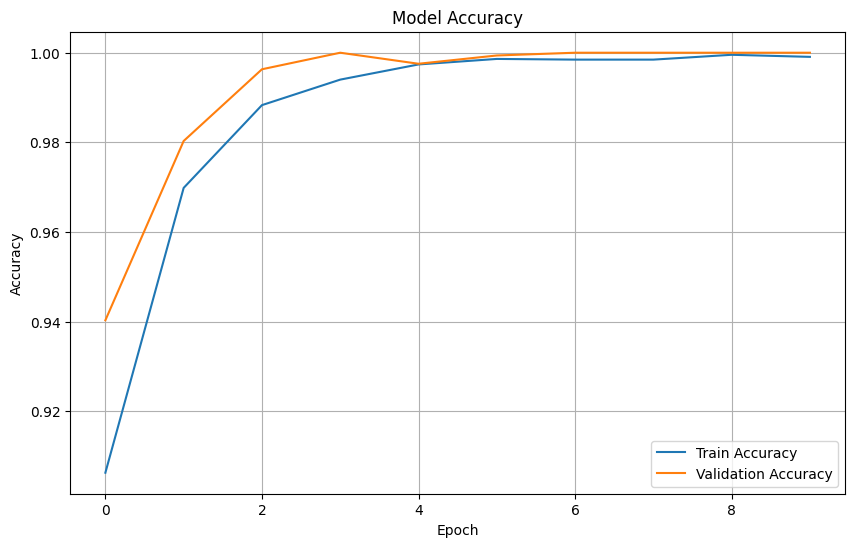

In [40]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

using the rnn model


In [47]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

rnn = Sequential([
    SimpleRNN(32, activation='tanh',
              input_shape=(X_train_dl.shape[1], 1)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

rnn.compile(optimizer='adam',
            loss='binary_crossentropy',
            metrics=['accuracy'])

rnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,177 (8.50 KB)

 Trainable params: 2,177 (8.50 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
# Train the RNN model
rnn_history = rnn.fit(
    X_train_dl,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test_dl, y_test)
)

# Evaluate the RNN model
rnn_loss, rnn_accuracy = rnn.evaluate(X_test_dl, y_test)
print(f"\nRNN Test Loss: {rnn_loss:.4f}")
print(f"RNN Test Accuracy: {rnn_accuracy:.4f}")

Epoch 1/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8283 - loss: 0.4227 - val_accuracy: 0.8997 - val_loss: 0.2903
Epoch 2/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9249 - loss: 0.1857 - val_accuracy: 0.9323 - val_loss: 0.1483
Epoch 3/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9472 - loss: 0.1084 - val_accuracy: 0.9649 - val_loss: 0.0759
Epoch 4/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9726 - loss: 0.0639 - val_accuracy: 0.9729 - val_loss: 0.0688
Epoch 5/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9791 - loss: 0.0525 - val_accuracy: 0.9877 - val_loss: 0.0337
Epoch 6/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9906 - loss: 0.0296 - val_accuracy: 0.9963 - val_loss: 0.0159
Epoch 7/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9955 - loss: 0.0146 - val_accuracy: 0.9920 - val_loss: 0.0178
Epoch 8/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9957 - loss: 0.0131 - val_accuracy: 0

51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
CONV1D CNN MODEL CLASSIFICATION REPORT:
               precision    recall  f1-score   support

   Edible (0)       1.00      1.00      1.00       843
Poisonous (1)       1.00      1.00      1.00       782

     accuracy                           1.00      1625
    macro avg       1.00      1.00      1.00      1625
 weighted avg       1.00      1.00      1.00      1625

SIMPLERNN MODEL CLASSIFICATION REPORT:
               precision    recall  f1-score   support

   Edible (0)       1.00      1.00      1.00       843
Poisonous (1)       1.00      1.00      1.00       782

     accuracy                           1.00      1625
    macro avg       1.00      1.00      1.00      1625
 weighted avg       1.00      1.00      1.00      1625



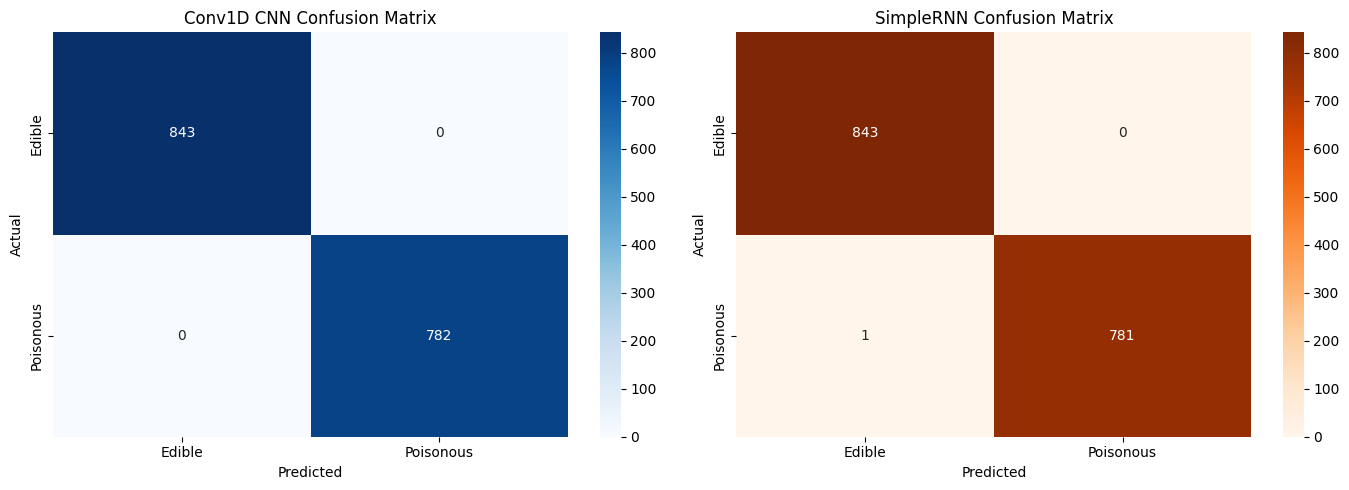

In [49]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Generate predictions for both models
cnn_preds = (model.predict(X_test_dl) > 0.5).astype("int32").flatten()
rnn_preds = (rnn.predict(X_test_dl) > 0.5).astype("int32").flatten()

# 2. Print Classification Reports
print("="*50)
print("CONV1D CNN MODEL CLASSIFICATION REPORT:")
print("="*50)
print(classification_report(y_test, cnn_preds, target_names=['Edible (0)', 'Poisonous (1)']))

print("="*50)
print("SIMPLERNN MODEL CLASSIFICATION REPORT:")
print("="*50)
print(classification_report(y_test, rnn_preds, target_names=['Edible (0)', 'Poisonous (1)']))

# 3. Calculate Confusion Matrices
cnn_cm = confusion_matrix(y_test, cnn_preds)
rnn_cm = confusion_matrix(y_test, rnn_preds)

# 4. Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cnn_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Edible', 'Poisonous'], yticklabels=['Edible', 'Poisonous'])
axes[0].set_title('Conv1D CNN Confusion Matrix')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

sns.heatmap(rnn_cm, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['Edible', 'Poisonous'], yticklabels=['Edible', 'Poisonous'])
axes[1].set_title('SimpleRNN Confusion Matrix')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.show()

In [51]:
import json

with open("exercise_text.json", "r") as f:
    data = json.load(f)

text = data["text"]
print(text)

In this exercise, you are required to Apply and evaluate CNN, ANN, and RNN models Compare their performance and identify the model that achieves the highest accuracy for image classification using the **Iris Flowers dataset**. You will load and preprocess image data, design a multi-layer CNN architecture using TensorFlow/Keras, and train the model to recognize different object categories. After training, you will evaluate the model's performance on unseen test data and visualize the training loss across epochs. The objective of this exercise is to provide hands-on experience with **Deep Learning and Computer Vision**, enabling you to understand the complete workflow of an image classification project. Also solve the Large Language Models (LLMs) Architecture & Work. And Using LLMs with LangChain, passing prompts programmatically.


In [52]:
%pip install transformers

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

tokens = tokenizer.tokenize(text)
ids = tokenizer.encode(text)

print("Number of tokens:", len(tokens))
print("Tokens:", tokens)
print("Token IDs:", ids)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Number of tokens: 173
Tokens: ['in', 'this', 'exercise', ',', 'you', 'are', 'required', 'to', 'apply', 'and', 'evaluate', 'cnn', ',', 'ann', ',', 'and', 'rn', '##n', 'models', 'compare', 'their', 'performance', 'and', 'identify', 'the', 'model', 'that', 'achieve', '##s', 'the', 'highest', 'accuracy', 'for', 'image', 'classification', 'using', 'the', '*', '*', 'iris', 'flowers', 'data', '##set', '*', '*', '.', 'you', 'will', 'load', 'and', 'prep', '##ro', '##ces', '##s', 'image', 'data', ',', 'design', 'a', 'multi', '-', 'layer', 'cnn', 'architecture', 'using', 'tensor', '##flow', '/', 'ke', '##ras', ',', 'and', 'train', 'the', 'model', 'to', 'recognize', 'different', 'object', 'categories', '.', 'after', 'training', ',', 'you', 'will', 'evaluate', 'the', 'model', "'", 's', 'performance', 'on', 'unseen', 'test', 'data', 'and', 'visual', '##ize', 'the', 'training', 'loss', 'across', 'epoch', '##s', '.', 'the', 'objective', 'of', 'this', 'exercise', 'is', 'to', 'provide', 'hands', '-', 'o